pip install tensorflow
pip install tf_slim
pip install tensorflow_hub
pip install opencv-python
pip install pillow
pip install lxml
pip install Cython
pip install contextlib2
pip install matplotlib
pip install pycocotools

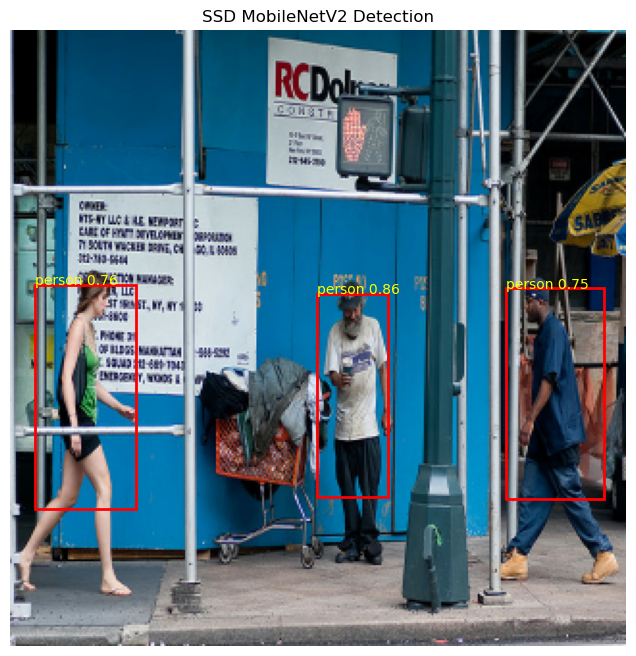

In [ ]:
import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import matplotlib.pyplot as plt

COCO_CLASS_NAMES = [
    'background', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat',
    'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse',
    'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase',
    'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard',
    'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana',
    'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch',
    'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone',
    'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear',
    'hair drier', 'toothbrush'
]

detector = hub.load("https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2")

img_path = 'human2.jpg'
img = tf.io.read_file(img_path)
img = tf.image.decode_jpeg(img, channels=3)
img_resized = tf.image.resize_with_pad(img, 320, 320)
img_resized = tf.cast(img_resized, tf.uint8) 

img_input = tf.expand_dims(img_resized, 0) 

# Deteksi objek
result = detector(img_input)
result = {key: value.numpy() for key, value in result.items()}

# Visualisasi
plt.figure(figsize=(8,8))
plt.imshow(tf.image.resize(img, (320, 320)).numpy().astype('uint8'))
h, w = 320, 320
for i in range(result['detection_boxes'].shape[1]):
    score = result['detection_scores'][0,i]
    if score < 0.7:
        continue
    ymin, xmin, ymax, xmax = result['detection_boxes'][0,i]
    (left, right, top, bottom) = (xmin*w, xmax*w, ymin*h, ymax*h)
    plt.gca().add_patch(plt.Rectangle(
        (left, top), right-left, bottom-top,
        fill=False, edgecolor='red', linewidth=2))
    label = int(result['detection_classes'][0,i])
    label_name = COCO_CLASS_NAMES[label] if 0 < label < len(COCO_CLASS_NAMES) else None
    if label_name is None:
        continue
    plt.text(left, top, f"{label_name} {score:.2f}", color='yellow', fontsize=10)

plt.axis('off')
plt.title("SSD MobileNetV2 Detection")
plt.show()